<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Web_Scraping_IA_Tienda_con_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 Web Scraping con IA — Catálogo de tienda online
Extraemos el **listado de productos de varias páginas** de una tienda (sitio de pruebas `webscraper.io`),
con **ScrapeGraphAI + GPT-4o-mini**, validamos los datos con un **esquema Pydantic**, los limpiamos con **pandas** y generamos **análisis, gráfica y Excel/CSV**.

> Sitio usado: sitio demo creado para practicar scraping. Si lo cambias por una tienda real, revisa sus *Términos de uso* y su `robots.txt`.

## 1️⃣ Instalación

In [ ]:
!pip install -q scrapegraphai pydantic openpyxl nest_asyncio
!playwright install-deps
!playwright install chromium

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
Installing dependencies...
Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:5 https://cli.github.com/packages stable/main amd64 Packages [356 B]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,088 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://r2u.stat.illinois.edu/ubu

## 2️⃣ Configuración (API Key, modelo y parámetros)

In [ ]:
import os, re, json, time
import nest_asyncio
nest_asyncio.apply()
import pandas as pd
import matplotlib.pyplot as plt
from typing import List
from pydantic import BaseModel, Field
from scrapegraphai.graphs import SmartScraperGraph

# --- API Key ---
try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    import getpass
    os.environ["OPENAI_API_KEY"] = getpass.getpass("Ingresa tu OpenAI API Key: ")

# --- Parámetros que puedes cambiar ---
BASE_URL   = "https://webscraper.io/test-sites/e-commerce/static/computers/laptops"
NUM_PAGES  = 3
PAUSA_SEG  = 2

graph_config = {
    "llm": {"model": "openai/gpt-4o-mini", "temperature": 0},
    "headless": True,
    "verbose": False,
    "playwright_params": {"args": ["--no-sandbox", "--disable-dev-shm-usage"]},
}

## 3️⃣ Esquema de datos (le decimos a la IA exactamente qué estructura devolver)

In [ ]:
class Producto(BaseModel):
    nombre: str = Field(description="Nombre o título del producto")
    precio_usd: str = Field(description="Precio tal como aparece, con símbolo de moneda")
    descripcion: str = Field(description="Descripción corta o especificaciones del producto")
    num_resenas: int = Field(description="Número de reseñas (solo el número). 0 si no hay")

class ListaProductos(BaseModel):
    productos: List[Producto] = Field(description="Todos los productos visibles en la página")

## 4️⃣ Función de scraping para una página

In [ ]:
PROMPT = """
Extrae TODOS los productos del listado que aparece en esta página de una tienda online.
Para cada producto devuelve: nombre, precio (con moneda), descripción corta y número de reseñas.
No inventes datos: si algo no aparece, usa un valor vacío o 0.
"""

def scrapear_pagina(url: str):
    scraper = SmartScraperGraph(
        prompt=PROMPT,
        source=url,
        config=graph_config,
        schema=ListaProductos,
    )
    resultado = scraper.run()
    # El resultado puede venir como {"content": {...}} o directamente como dict
    if isinstance(resultado, dict) and "content" in resultado:
        resultado = resultado["content"]
    return resultado.get("productos", []) if isinstance(resultado, dict) else []

## 5️⃣ Recorrer varias páginas (paginación)

In [ ]:
todos = []

for pagina in range(1, NUM_PAGES + 1):
    url = f"{BASE_URL}?page={pagina}"
    print(f" Página {pagina}/{NUM_PAGES} → {url}")
    try:
        items = scrapear_pagina(url)
        for it in items:
            it["pagina"] = pagina
        todos.extend(items)
        print(f"   {len(items)} productos extraídos")
    except Exception as e:
        print(f"   Error en la página {pagina}: {e}")
    time.sleep(PAUSA_SEG)

print(f"\n Total de productos extraídos: {len(todos)}")
if not todos:
    raise SystemExit("No se extrajo ningún producto. Revisa los errores de arriba antes de continuar.")

⏳ Página 1/3 → https://webscraper.io/test-sites/e-commerce/static/computers/laptops?page=1
   ✅ 6 productos extraídos
⏳ Página 2/3 → https://webscraper.io/test-sites/e-commerce/static/computers/laptops?page=2
   ✅ 6 productos extraídos
⏳ Página 3/3 → https://webscraper.io/test-sites/e-commerce/static/computers/laptops?page=3
   ✅ 6 productos extraídos

🎯 Total de productos extraídos: 18


## 6️⃣ Limpieza de datos con pandas

In [ ]:
df = pd.DataFrame(todos)

# Precio a número (ej. "$295.99" -> 295.99)
df["precio"] = (df["precio_usd"].astype(str)
                .str.replace(r"[^0-9.]", "", regex=True)
                .astype(float))

# Marca = primera palabra del nombre
df["marca"] = df["nombre"].str.split().str[0].str.title()

# Eliminar duplicados y ordenar
df = df.drop_duplicates(subset=["nombre",
                                "precio"]).sort_values("precio").reset_index(drop=True)

df[["nombre", "marca", "precio", "num_resenas", "pagina"]].head(15)

,nombre,marca,precio,num_resenas,pagina
0,Aspire E1-510,Aspire,306.99,2,1
1,Asus VivoBook Max,Asus,399.00,4,3
2,Packard 255 G2,Packard,416.99,2,1
3,Dell Vostro 15,Dell,488.78,14,3
4,HP 250 G3,Hp,520.99,13,2
5,Acer Spin 5,Acer,564.98,0,3
6,HP 350 G1,Hp,577.99,0,3
7,Aspire E1-572G,Aspire,581.99,2,1
8,Pavilion,Pavilion,609.99,4,2
9,Acer Aspire A515-51-5654,Acer,679.00,9,3


## 7️⃣ Análisis rápido

In [ ]:
print("💰 Los 5 más baratos")
display(df[["nombre", "precio", "num_resenas"]].head(5))

print("\n⭐ Los 5 con más reseñas")
display(df.nlargest(5, "num_resenas")[["nombre", "precio", "num_resenas"]])

print("\n🏷️ Precio promedio por marca")
resumen = (df.groupby("marca")
             .agg(productos=("nombre", "count"), precio_promedio=("precio", "mean"))
             .round(2).sort_values("precio_promedio"))
display(resumen)

💰 Los 5 más baratos


,nombre,precio,num_resenas
0,Aspire E1-510,306.99,2
1,Asus VivoBook Max,399.00,4
2,Packard 255 G2,416.99,2
3,Dell Vostro 15,488.78,14
4,HP 250 G3,520.99,13



⭐ Los 5 con más reseñas


,nombre,precio,num_resenas
3,Dell Vostro 15,488.78,14
4,HP 250 G3,520.99,13
12,ThinkPad Yoga,1033.99,13
11,Inspiron 15,745.99,12
17,ThinkPad X240,1311.99,12



🏷️ Precio promedio por marca


,productos,precio_promedio
marca,,
Asus,1,399.00
Packard,1,416.99
Aspire,2,444.49
Hp,2,549.49
Pavilion,1,609.99
Acer,2,621.99
Probook,1,739.99
Inspiron,1,745.99
Dell,2,885.38


## 8️⃣ Gráfica

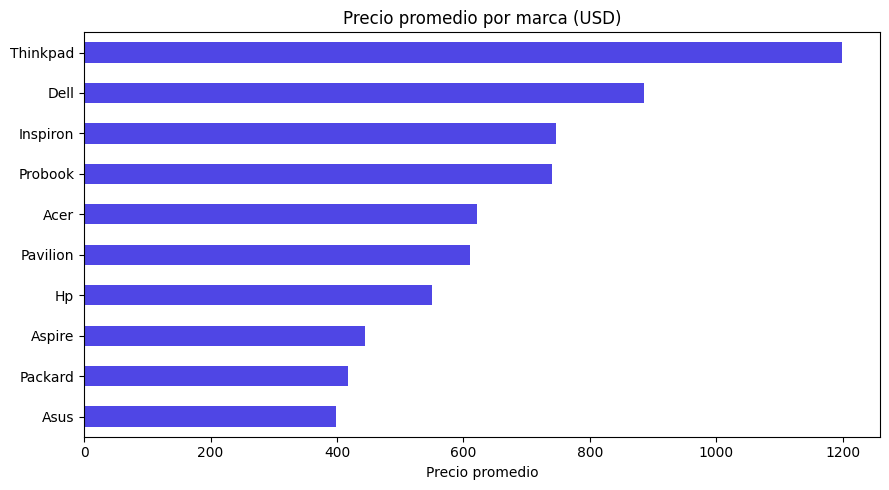

In [ ]:
plt.figure(figsize=(9, 5))
resumen["precio_promedio"].plot(kind="barh", color="#4F46E5")
plt.title("Precio promedio por marca (USD)")
plt.xlabel("Precio promedio")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 9️⃣ Exportar resultados (CSV + Excel) y descargar

In [ ]:
df.to_csv("productos.csv", index=False, encoding="utf-8-sig")
df.to_excel("productos.xlsx", index=False)

try:
    from google.colab import files
    files.download("productos.xlsx")
    files.download("productos.csv")
except Exception:
    print("Archivos guardados: productos.csv y productos.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>